<a href="https://www.kaggle.com/code/nicapotato/guided-bakery-customer-analysis?scriptVersionId=363172224" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Order & Customer Exploration — Historical Bakery Sales
_Baskets, visit calendars, and customer personas in a two-year, three-store ledger_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [sdcloud/historical-bakery-sales-dataset](https://www.kaggle.com/datasets/sdcloud/historical-bakery-sales-dataset)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***


# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Order Profiles](#Orders)** <br>
**5. [Customer Profiles](#Customers)** <br>
**6. [What They Buy](#Category)** <br>
**7. [Correlations](#Correlations)** <br>
**8. [What Moves the Ticket](#Ticket)** <br>
**9. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one product line on a bakery ticket: 19,321 lines, 6,576 orders, 500 customers, 1 Jan 2023 through 31 Dec 2024, three stores. Festival names (Diwali, Holi, Ganesh Chaturthi) and products such as paav and nankhatai place the ledger in an Indian bakery. Age, gender, segment, and loyalty never change for a given customer — they are a profile stamped onto every line, not a trait that updates between visits.

The question is which grain carries the pattern. Line items answer product economics. Orders answer the basket and the calendar. Customers answer whether those 500 personas actually buy differently. Blank `Festival` and `Promotion_Type` values are structural (no festival that day, no promotion on that order), so they are labeled `"None"` rather than imputed.


# **2. Setup and Data Peek:** <a id="Setup"></a>


In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
sns.set_palette([
    "#30a2da",
    "#fc4f30",
    "#e5ae38",
    "#6d904f",
    "#8b8b8b",
])
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` tests group differences and rank correlations; `sklearn` fits one linear model of the order bill. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration.


In [2]:
# Read and peek at the ledger
CSV_BASENAME = "bakery_sales_dataset.csv"
KAGGLE_SLUG = "sdcloud/historical-bakery-sales-dataset"
SEG_ORDER = ["Student", "Young Professional", "Family", "Senior Citizen"]
DOW_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
PERISH_ORDER = ["Low", "Medium", "High", "Very High"]
CAT_ORDER = [
    "Cakes", "Indian Bakery", "Dairy & Spreads", "Pastry & Sweet",
    "Beverages", "Bread & Daily", "Savoury Bakery",
]
# Fields that describe the visit, not the product line. Each must be constant inside an order.
ORDER_CONST = [
    "Customer_ID", "Customer_Age", "Customer_Gender", "Customer_Segment",
    "Loyalty_Member", "Date", "Day_of_Week", "Weekend", "Hour", "Season",
    "Weather", "Temperature", "Payment_Method", "Store_ID", "Customer_Rating",
    "Festival", "Promotion_Applied",
]
EXPECTED = [
    "Order_ID", "Customer_ID", "Customer_Age", "Customer_Gender", "Customer_Segment",
    "Loyalty_Member", "Date", "Year", "Month", "Day", "Day_of_Week", "Weekend", "Hour",
    "Time", "Season", "Festival", "Weather", "Temperature", "Product", "Category",
    "Quantity", "Unit_Price", "Cost_Price", "Discount_Percentage", "Selling_Price",
    "Total_Bill", "Payment_Method", "Promotion_Applied", "Promotion_Type",
    "Shelf_Life_Days", "Storage_Type", "Perishability", "Store_ID", "Units_Produced",
    "Units_Sold", "Unsold_Units", "Stock_Available", "Waste_Pct", "Profit", "Customer_Rating",
]


def resolve_csv_path(basename: str = CSV_BASENAME) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(KAGGLE_SLUG))
    p = root / basename
    if not p.exists():
        hits = list(root.rglob(basename))
        assert hits, f"expected {basename} under {root}"
        p = hits[0]
    return p


csv_path = resolve_csv_path()
print("CSV:", csv_path)
df = pd.read_csv(csv_path, low_memory=False)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (19321, 40), df.shape
assert df["Order_ID"].nunique() == 6576
assert df["Customer_ID"].nunique() == 500

print("Nulls before structural fill:")
nulls = df.isnull().sum()
print(nulls[nulls > 0].to_string())

# Promotion_Type is blank exactly when the order was not promoted — a label, not a hole
assert df.loc[df["Promotion_Applied"] == "No", "Promotion_Type"].isna().all()
assert df.loc[df["Promotion_Applied"] == "Yes", "Promotion_Type"].notna().all()
for col in ORDER_CONST:
    nunique = df.groupby("Order_ID")[col].nunique(dropna=False)
    assert int(nunique.max()) == 1, col

df["Festival"] = df["Festival"].fillna("None")
df["Promotion_Type"] = df["Promotion_Type"].fillna("None")
assert int(df.isnull().sum().sum()) == 0

df["Date"] = pd.to_datetime(df["Date"])
assert df["Date"].min() == pd.Timestamp("2023-01-01")
assert df["Date"].max() == pd.Timestamp("2024-12-31")
df["Customer_Segment"] = pd.Categorical(df["Customer_Segment"], SEG_ORDER, ordered=True)
df["Day_of_Week"] = pd.Categorical(df["Day_of_Week"], DOW_ORDER, ordered=True)
df["Perishability"] = pd.Categorical(df["Perishability"], PERISH_ORDER, ordered=True)
df["Category"] = pd.Categorical(df["Category"], CAT_ORDER, ordered=True)

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print("Orders:", df["Order_ID"].nunique(), "| Customers:", df["Customer_ID"].nunique())
print("Dates:", df["Date"].min().date(), "->", df["Date"].max().date())
display(df.dtypes.to_frame("dtype"))
display(df.sample(5, random_state=7))


CSV: /kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv
Nulls before structural fill:
Festival          16006
Promotion_Type    13826
Dataframe Dimension: 19321 Rows, 40 Columns
Orders: 6576 | Customers: 500
Dates: 2023-01-01 -> 2024-12-31


,dtype
Order_ID,object
Customer_ID,object
Customer_Age,int64
Customer_Gender,object
Customer_Segment,category
Loyalty_Member,object
Date,datetime64[ns]
Year,int64
Month,int64
Day,int64


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,Day_of_Week,Weekend,Hour,Time,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Shelf_Life_Days,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
12793,ORD04294,CUST0024,30,Male,Student,No,2024-04-27,2024,4,27,Saturday,Yes,12,12:11,Summer,None,Hot,43.0,Pastry,Pastry & Sweet,3,57.26,29.05,0.0,57.26,171.78,UPI,No,None,1,Refrigerated,Very High,ST02,4,3,1,1,25.0,84.63,4
13573,ORD04572,CUST0497,51,Female,Family,Yes,2024-05-27,2024,5,27,Monday,No,13,13:56,Summer,None,Clear,44.9,Milk,Dairy & Spreads,2,29.17,21.19,0.0,29.17,58.34,Cash,No,None,6,Refrigerated,High,ST03,3,2,1,1,33.3,15.96,4
12890,ORD04331,CUST0139,37,Male,Young Professional,Yes,2024-04-30,2024,4,30,Tuesday,No,8,8:40,Summer,None,Clear,30.9,Cookies,Indian Bakery,12,117.26,56.09,0.0,117.26,1407.12,UPI,No,None,51,Dry Storage,Low,ST02,17,12,5,5,29.4,734.04,3
3185,ORD01098,CUST0218,26,Other,Student,No,2023-05-06,2023,5,6,Saturday,Yes,12,12:20,Summer,None,Hot,43.7,Milk,Dairy & Spreads,2,28.60,20.44,0.0,28.60,57.20,UPI,No,None,7,Refrigerated,High,ST02,3,2,1,1,33.3,16.32,5
16089,ORD05482,CUST0373,59,Female,Senior Citizen,Yes,2024-09-08,2024,9,8,Sunday,Yes,13,13:10,Monsoon,Ganesh Chaturthi,Humid,31.1,Cookies,Indian Bakery,4,125.64,62.62,0.0,125.64,502.56,Cash,No,None,91,Dry Storage,Low,ST01,8,7,1,1,12.5,252.08,4


**Code Explanation and Reasoning:** <br>
Shape, column set, and the 6,576 / 500 grain are asserted. Visit fields (who, when, where, how they paid, the rating) are checked to be constant inside each `Order_ID` before any rollup — including a missing festival, which counts as one level.

`Festival` and `Promotion_Type` blanks are then labeled `"None"`. That is the explicit "no event" level, paired with `Promotion_Applied == "No"` for the promotion column. It is not a guess at a festival name or a promo type.


In [3]:
unique_count = [
    [c, df[c].nunique(dropna=False), int(df[c].isnull().sum())] for c in df.columns
]
display(
    pd.DataFrame(unique_count, columns=["Column", "Unique", "Null"])
    .sort_values("Unique", ascending=False)
    .reset_index(drop=True)
)
display(
    df[["Customer_Age", "Quantity", "Unit_Price", "Total_Bill", "Profit",
        "Waste_Pct", "Discount_Percentage", "Customer_Rating"]]
    .describe()
    .round(2)
)


,Column,Unique,Null
0,Total_Bill,11349,0
1,Selling_Price,8657,0
2,Profit,8460,0
3,Unit_Price,7711,0
4,Order_ID,6576,0
5,Cost_Price,6232,0
6,Time,872,0
7,Date,731,0
8,Customer_ID,500,0
9,Shelf_Life_Days,498,0


,Customer_Age,Quantity,Unit_Price,Total_Bill,Profit,Waste_Pct,Discount_Percentage,Customer_Rating
count,19321.00,19321.00,19321.00,19321.00,19321.00,19321.00,19321.00,19321.00
mean,35.54,2.23,87.26,139.27,59.20,34.12,4.35,3.83
std,13.73,1.78,110.48,157.77,65.24,12.73,6.79,0.95
min,16.00,1.00,7.60,13.12,-0.55,4.20,0.00,1.00
25%,25.00,1.00,31.02,52.12,20.69,25.00,0.00,3.00
50%,34.00,2.00,45.09,82.80,36.76,33.30,0.00,4.00
75%,45.00,3.00,76.65,146.54,65.92,50.00,7.50,4.00
max,73.00,20.00,472.42,1885.96,767.60,50.00,30.00,5.00


**Interpretation** <br>
The ledger is complete after the structural labels: no remaining nulls. Line bills are right-skewed (median about 83, mean about 139, max near 1,900). Ratings pile up at 4 and 5. Waste sits high — median 33%, and nothing in the table is below about 4%. Quantity is small (median 2 units on a line). Those shapes are line-item facts; the next sections re-aggregate before treating them as orders or people.


# **3. Univariate Distributions:** <a id="Univariate"></a>


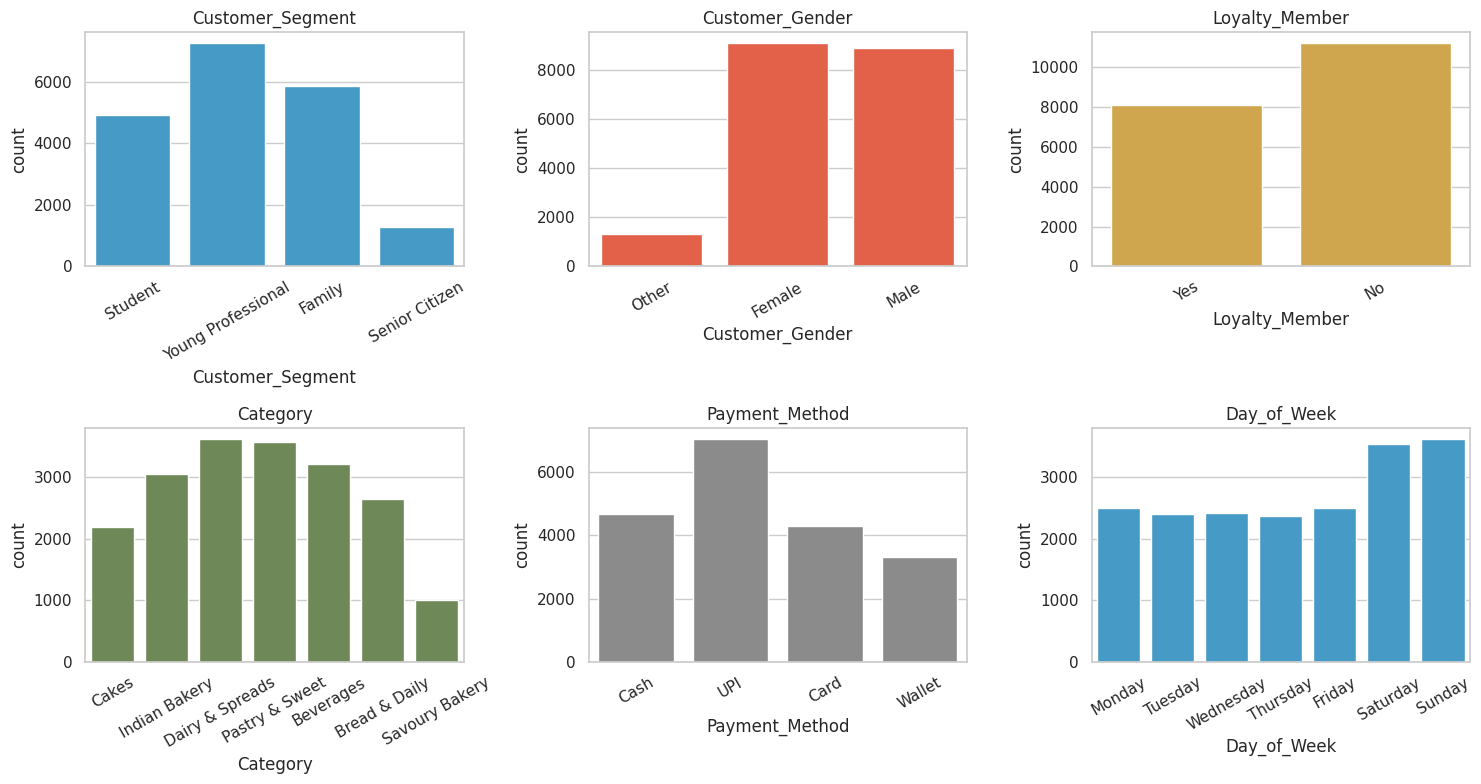

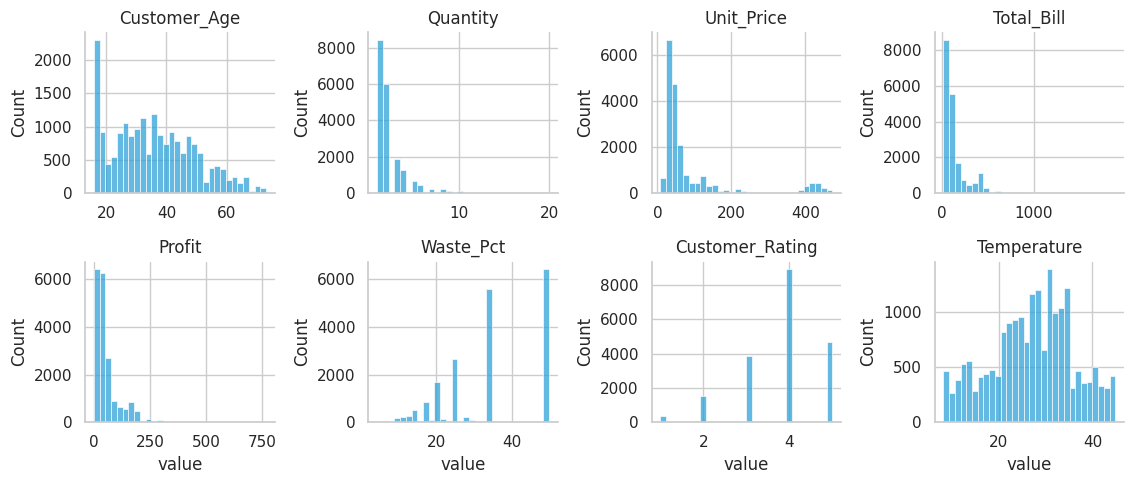

Line items by season: {'Monsoon': 6466, 'Summer': 4831, 'Winter': 4777, 'Autumn': 3247}
Line items by store: {'ST01': 6668, 'ST02': 6332, 'ST03': 6321}
Line items by weekend: {'No': 12180, 'Yes': 7141}


In [4]:
# Line-item counts. Multi-line orders are counted once per product, so busy baskets weigh more.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col, color in [
    (axes[0], "Customer_Segment", "#30a2da"),
    (axes[1], "Customer_Gender", "#fc4f30"),
    (axes[2], "Loyalty_Member", "#e5ae38"),
    (axes[3], "Category", "#6d904f"),
    (axes[4], "Payment_Method", "#8b8b8b"),
    (axes[5], "Day_of_Week", "#30a2da"),
]:
    sns.countplot(data=df, x=col, ax=ax, color=color)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

num_panel = [
    "Customer_Age", "Quantity", "Unit_Price", "Total_Bill",
    "Profit", "Waste_Pct", "Customer_Rating", "Temperature",
]
melt = df[num_panel].melt(var_name="feature", value_name="value")
g = sns.FacetGrid(
    melt, col="feature", col_wrap=4, sharex=False, sharey=False, height=2.5, aspect=1.15,
)
g.map_dataframe(sns.histplot, x="value", bins=30, color="#30a2da")
g.set_titles("{col_name}")
plt.show()

print("Line items by season:", df["Season"].value_counts().to_dict())
print("Line items by store:", df["Store_ID"].value_counts().to_dict())
print("Line items by weekend:", df["Weekend"].value_counts().to_dict())


**Interpretation** <br>
Young professionals and families dominate the line items; senior citizens are a thin slice. Loyalty is the minority class. Dairy, pastry, and beverages lead line counts, which is not the same thing as leading revenue — cakes are fewer lines and, later, most of the money. Saturday and Sunday are the heavy days even at line grain. Unit price, line bill, and profit share one long right tail; age is the only demographic that actually spreads out, which is the clue that "segment" may just be an age persona.

These charts count lines. A 7-line order shouts seven times. Order and customer sections below each count a ticket or a person once.


# **4. Order Profiles:** <a id="Orders"></a>


Orders: 6576
Lines per order:
 count    6576.00
mean        2.94
std         1.46
min         1.00
25%         2.00
50%         3.00
75%         4.00
max         7.00
Order bill:
 count    6576.0
mean      409.2
std       370.8
min        15.7
25%       156.6
50%       301.2
75%       553.2
max      3962.3
Weekend median bill 335.2 (n=2328) vs weekday 286.5 (n=4248)
Mann-Whitney U p-value (weekend vs weekday bill): 1.472e-06
Mean lines — weekday 2.87 | weekend 3.07

Festival vs not:


,count,median,mean
on_festival,,,
Festival,1047,450.9,588.7
No festival,5529,280.6,375.2


Promotion vs not:


,count,median,mean
promo,,,
No,4762,293.9,398.0
Yes,1814,322.8,438.6


,count,median,mean
festival,,,
None,5529,280.6,375.2
Holi,86,361.8,421.6
Ganesh Chaturthi,301,390.8,513.5
Independence Day,86,408.0,564.0
Republic Day,85,430.3,509.4
Eid,95,460.9,635.3
New Year,78,489.3,644.3
Dussehra,92,513.4,646.9
Diwali,138,545.6,740.0


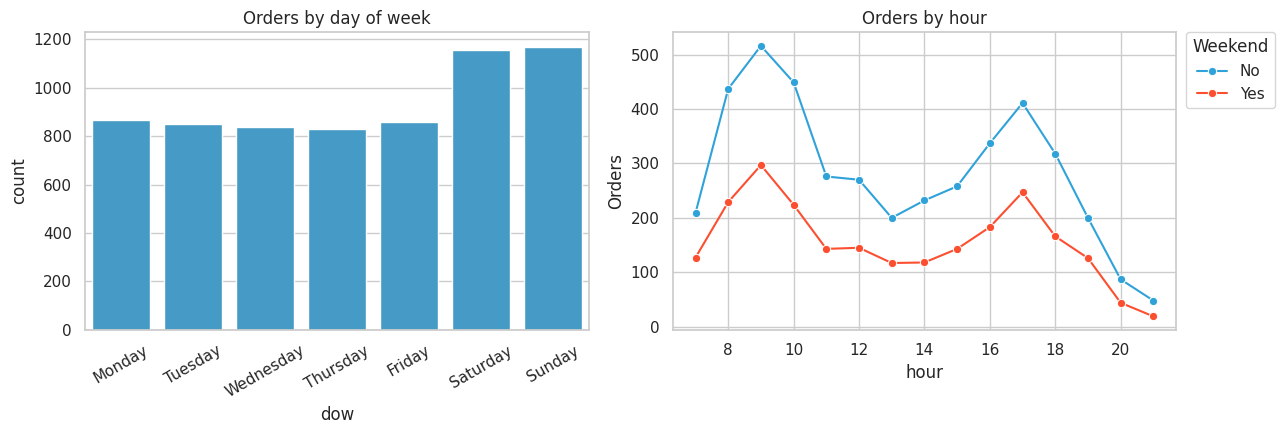

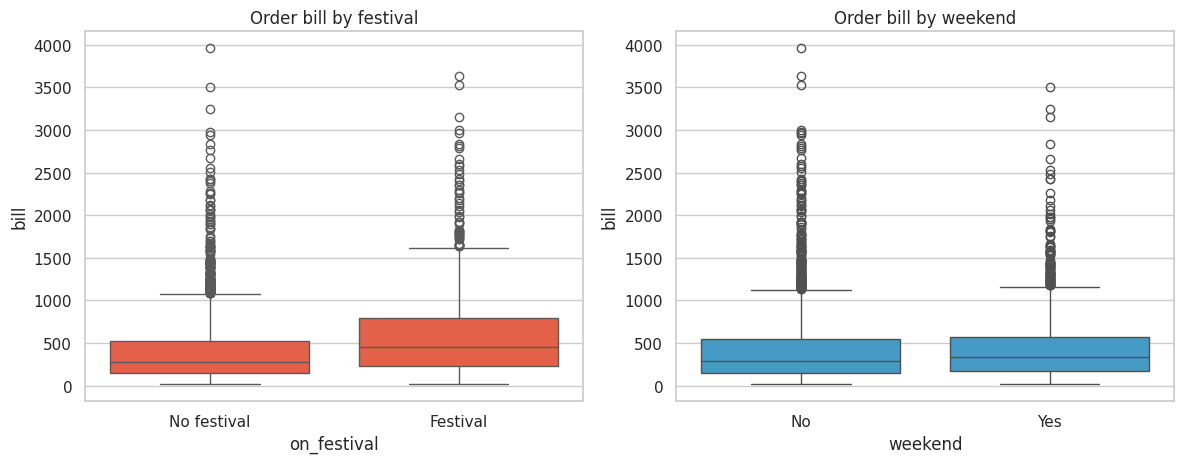

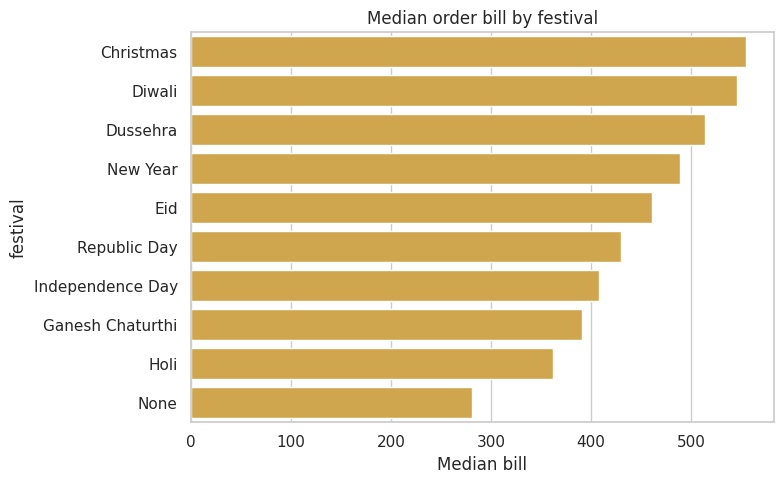

Payment mix within segment (row share of orders):


pay,Card,Cash,UPI,Wallet
segment,,,,
Student,25%,22%,36%,17%
Young Professional,23%,25%,36%,17%
Family,19%,26%,38%,18%
Senior Citizen,22%,22%,39%,17%


Store × segment row shares (orders):


segment,Student,Young Professional,Family,Senior Citizen
store,,,,
ST01,26%,37%,30%,7%
ST02,27%,37%,29%,6%
ST03,25%,39%,29%,7%


In [5]:
# One row per ticket. Sums are the basket; first() is safe because visit fields were asserted constant.
orders = df.groupby("Order_ID", as_index=False).agg(
    customer=("Customer_ID", "first"),
    age=("Customer_Age", "first"),
    gender=("Customer_Gender", "first"),
    segment=("Customer_Segment", "first"),
    loyalty=("Loyalty_Member", "first"),
    dow=("Day_of_Week", "first"),
    weekend=("Weekend", "first"),
    hour=("Hour", "first"),
    season=("Season", "first"),
    festival=("Festival", "first"),
    pay=("Payment_Method", "first"),
    store=("Store_ID", "first"),
    rating=("Customer_Rating", "first"),
    promo=("Promotion_Applied", "first"),
    lines=("Product", "count"),
    qty=("Quantity", "sum"),
    bill=("Total_Bill", "sum"),
    profit=("Profit", "sum"),
)
assert len(orders) == 6576
assert orders["customer"].nunique() == 500
orders["segment"] = pd.Categorical(orders["segment"], SEG_ORDER, ordered=True)
orders["dow"] = pd.Categorical(orders["dow"], DOW_ORDER, ordered=True)
orders["on_festival"] = np.where(orders["festival"].eq("None"), "No festival", "Festival")

print("Orders:", len(orders))
print("Lines per order:\n", orders["lines"].describe().round(2).to_string())
print("Order bill:\n", orders["bill"].describe().round(1).to_string())

weekend_bill = orders.loc[orders["weekend"] == "Yes", "bill"]
weekday_bill = orders.loc[orders["weekend"] == "No", "bill"]
mann = stats.mannwhitneyu(weekend_bill, weekday_bill, alternative="two-sided")
print(
    f"Weekend median bill {weekend_bill.median():.1f} (n={len(weekend_bill)}) "
    f"vs weekday {weekday_bill.median():.1f} (n={len(weekday_bill)})"
)
print(f"Mann-Whitney U p-value (weekend vs weekday bill): {mann.pvalue:.3e}")
print("Mean lines — weekday", round(orders.loc[orders["weekend"] == "No", "lines"].mean(), 2),
      "| weekend", round(orders.loc[orders["weekend"] == "Yes", "lines"].mean(), 2))

print("\nFestival vs not:")
display(orders.groupby("on_festival")["bill"].agg(["count", "median", "mean"]).round(1))
print("Promotion vs not:")
display(orders.groupby("promo")["bill"].agg(["count", "median", "mean"]).round(1))
fest_tbl = (
    orders.groupby("festival")["bill"].agg(["count", "median", "mean"]).sort_values("median")
)
display(fest_tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=orders, x="dow", order=DOW_ORDER, color="#30a2da", ax=axes[0])
axes[0].set_title("Orders by day of week")
axes[0].tick_params(axis="x", rotation=30)
hour_counts = (
    orders.groupby(["hour", "weekend"], observed=True).size().reset_index(name="n_orders")
)
sns.lineplot(
    data=hour_counts, x="hour", y="n_orders", hue="weekend",
    hue_order=["No", "Yes"], marker="o", ax=axes[1],
)
axes[1].legend(title="Weekend", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
axes[1].set_title("Orders by hour")
axes[1].set_ylabel("Orders")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.boxplot(
    data=orders, x="on_festival", y="bill",
    order=["No festival", "Festival"], color="#fc4f30", ax=axes[0],
)
axes[0].set_title("Order bill by festival")
sns.boxplot(
    data=orders, x="weekend", y="bill", order=["No", "Yes"], color="#30a2da", ax=axes[1],
)
axes[1].set_title("Order bill by weekend")
plt.tight_layout()
plt.show()

fest_order = fest_tbl.sort_values("median", ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=orders, x="bill", y="festival", order=fest_order,
    estimator="median", errorbar=None, color="#e5ae38", ax=ax,
)
ax.set_title("Median order bill by festival")
ax.set_xlabel("Median bill")
plt.tight_layout()
plt.show()

print("Payment mix within segment (row share of orders):")
pay_share = (
    pd.crosstab(orders["segment"], orders["pay"], normalize="index").reindex(index=SEG_ORDER)
)
display(pay_share.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))
print("Store × segment row shares (orders):")
store_share = (
    pd.crosstab(orders["store"], orders["segment"], normalize="index").reindex(columns=SEG_ORDER)
)
display(store_share.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))


**Interpretation** <br>
A typical ticket is 3 lines (never more than 7) and a median bill near 300, with a long tail out past 3,000. The mean bill (about 409) sits well above the median, so a handful of rich tickets pull the average.

The calendar moves the median more than the persona will. Every named festival clears the off-festival median (about 281). Ganesh Chaturthi supplies the most festival orders; Diwali and Christmas have the richest medians (about 550). Taken together, festival orders median about 451 versus 281 off festival. A promotion's raw median gap is smaller (about 323 versus 294), and festival orders are usually promoted, so the promo flag partly restates the festival.

Weekends are busier (Saturday and Sunday each clear 1,100 orders; weekdays sit near 850) and their median bill is higher (about 335 versus 287; Mann–Whitney p well under 0.001). Mean basket length is only slightly higher on the weekend (about 3.07 versus 2.87 lines). Traffic peaks at 09:00 and again at 17:00, and thins out after 20:00. UPI is the leading tender in every segment, and the three stores carry the same persona mix — store is not a separate profile axis. The regression in section 8 asks whether the weekend median gap survives once basket length and festival are held constant.


# **5. Customer Profiles:** <a id="Customers"></a>


Customer personas:


,customers,median_age,age_min,age_max,loyalty_rate,median_orders,median_spend,median_ticket,mean_rating
segment,,,,,,,,,
Student,130,18,16,34,44%,13,4969,386,3.83
Young Professional,192,32,22,54,37%,13,5090,387,3.82
Family,143,45,35,73,45%,13,5374,404,3.83
Senior Citizen,35,60,55,72,37%,13,4689,346,3.82


Loyalty (customer grain):


,n_orders,spend,avg_bill,avg_rating
loyalty,,,,
No,13.0,4950.4,390.2,3.8
Yes,13.0,5267.2,392.9,3.8


Loyal customers: 206 of 500


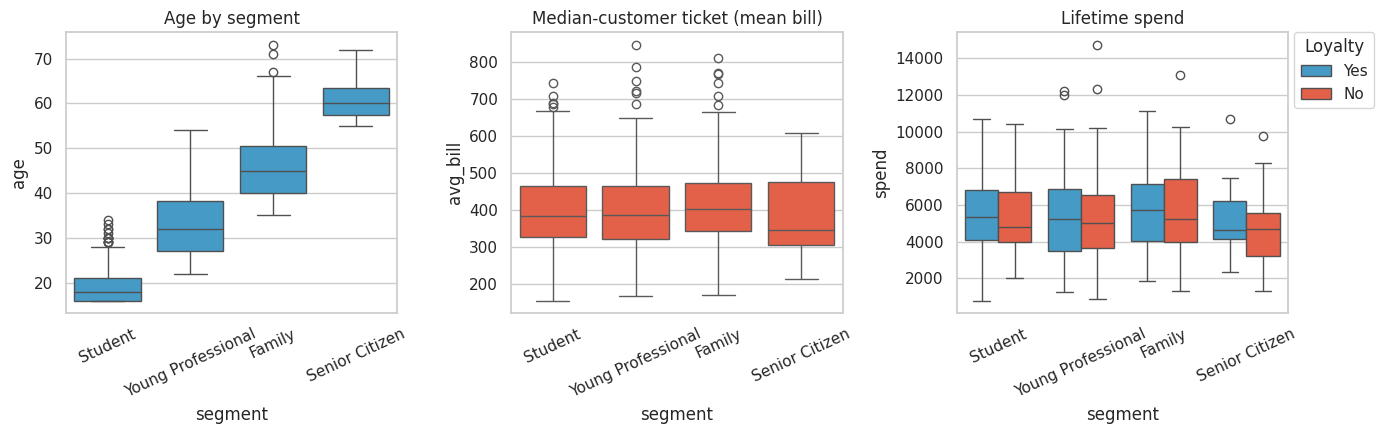

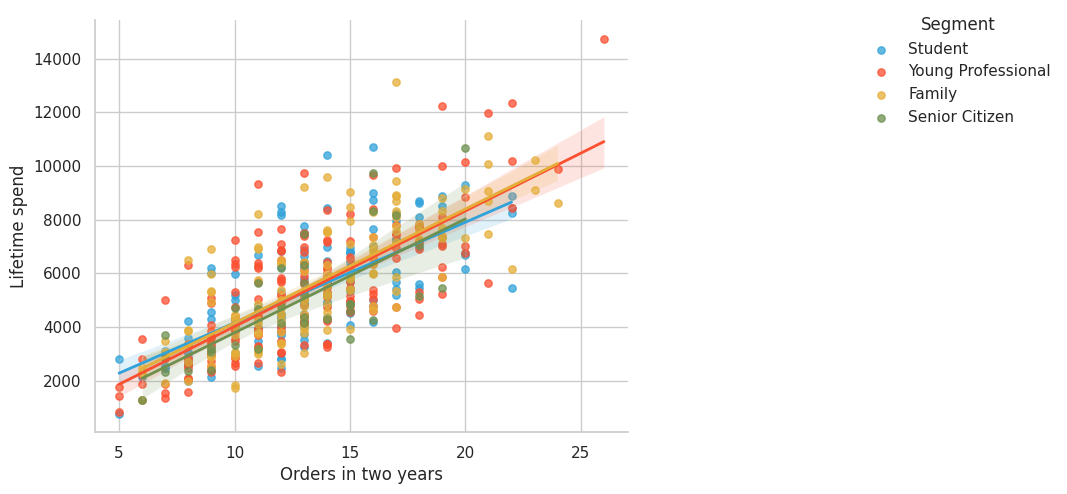

Spearman orders vs lifetime spend: rho=0.733, p=2.094e-85
Gender → segment, customer counts:


segment,Student,Young Professional,Family,Senior Citizen
gender,,,,
Female,60,79,72,19
Male,57,103,61,15
Other,13,10,10,1


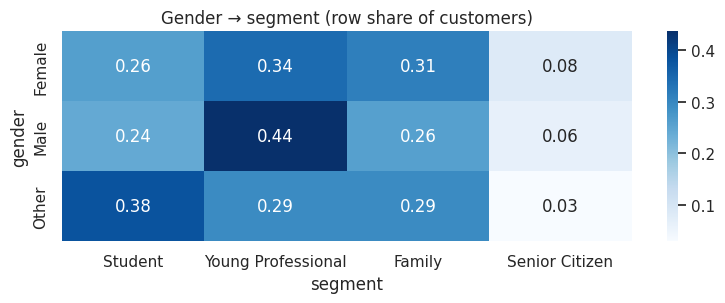

In [6]:
# One row per person. Age, gender, segment, and loyalty were constant across that person's orders.
profile_n = orders.groupby("customer")[["age", "gender", "segment", "loyalty"]].nunique()
assert int(profile_n.max().max()) == 1

customers = orders.groupby("customer", as_index=False).agg(
    age=("age", "first"),
    gender=("gender", "first"),
    segment=("segment", "first"),
    loyalty=("loyalty", "first"),
    n_orders=("Order_ID", "nunique"),
    spend=("bill", "sum"),
    avg_bill=("bill", "mean"),
    avg_lines=("lines", "mean"),
    avg_rating=("rating", "mean"),
)
assert len(customers) == 500
assert int(customers["n_orders"].sum()) == 6576
customers["segment"] = pd.Categorical(customers["segment"], SEG_ORDER, ordered=True)
customers["is_loyal"] = (customers["loyalty"] == "Yes").astype(int)

persona = customers.groupby("segment", observed=True).agg(
    customers=("customer", "size"),
    median_age=("age", "median"),
    age_min=("age", "min"),
    age_max=("age", "max"),
    loyalty_rate=("is_loyal", "mean"),
    median_orders=("n_orders", "median"),
    median_spend=("spend", "median"),
    median_ticket=("avg_bill", "median"),
    mean_rating=("avg_rating", "mean"),
)
print("Customer personas:")
display(
    persona.style.format({
        "loyalty_rate": "{:.0%}",
        "median_age": "{:.0f}",
        "median_orders": "{:.0f}",
        "median_spend": "{:.0f}",
        "median_ticket": "{:.0f}",
        "mean_rating": "{:.2f}",
    }).background_gradient(cmap="Blues", axis=0)
)
print("Loyalty (customer grain):")
display(
    customers.groupby("loyalty")[["n_orders", "spend", "avg_bill", "avg_rating"]]
    .median()
    .round(1)
)
print("Loyal customers:", int(customers["is_loyal"].sum()), "of", len(customers))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
sns.boxplot(data=customers, x="segment", y="age", order=SEG_ORDER, color="#30a2da", ax=axes[0])
axes[0].set_title("Age by segment")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=customers, x="segment", y="avg_bill", order=SEG_ORDER, color="#fc4f30", ax=axes[1])
axes[1].set_title("Median-customer ticket (mean bill)")
axes[1].tick_params(axis="x", rotation=25)
sns.boxplot(
    data=customers, x="segment", y="spend", hue="loyalty", order=SEG_ORDER, ax=axes[2],
)
axes[2].legend(title="Loyalty", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
axes[2].set_title("Lifetime spend")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

g = sns.lmplot(
    data=customers, x="n_orders", y="spend", hue="segment", hue_order=SEG_ORDER,
    height=5, aspect=1.35,
    scatter_kws={"alpha": 0.75, "s": 28},
    line_kws={"lw": 2},
)
g.set_axis_labels("Orders in two years", "Lifetime spend")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Segment", frameon=False)
plt.show()
rho, p = stats.spearmanr(customers["n_orders"], customers["spend"])
print(f"Spearman orders vs lifetime spend: rho={rho:.3f}, p={p:.3e}")

print("Gender → segment, customer counts:")
gender_n = pd.crosstab(customers["gender"], customers["segment"]).reindex(columns=SEG_ORDER)
display(gender_n)
gender_share = pd.crosstab(
    customers["gender"], customers["segment"], normalize="index",
).reindex(columns=SEG_ORDER)
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.heatmap(gender_share, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Gender → segment (row share of customers)")
plt.tight_layout()
plt.show()


**Interpretation** <br>
There are 500 people, not 19,321. Segments are age personas with soft edges: students center in the late teens, young professionals in the early 30s, families in the mid-40s, seniors around 60. Young professional still reaches into student ages and into family ages, so the label is a persona, not a hard cut. Median visit count is 13 orders in every segment (range across people is about 5 to 26).

Lifetime spend mostly tracks how often someone comes (Spearman ρ about 0.73). Loyalty (206 of 500) does not buy a higher median ticket or a higher median visit count. The one persona gap worth keeping is the senior ticket: their median average bill is lighter (about 346 versus about 404 for families). Ratings sit near 3.8 for every segment and do not move with spend. Men tilt a bit toward young professional and the small Other group tilts toward student; neither rewrite the flat ticket story. Gender row-shares are a composition fact, not a spending fact.


# **6. What They Buy:** <a id="Category"></a>


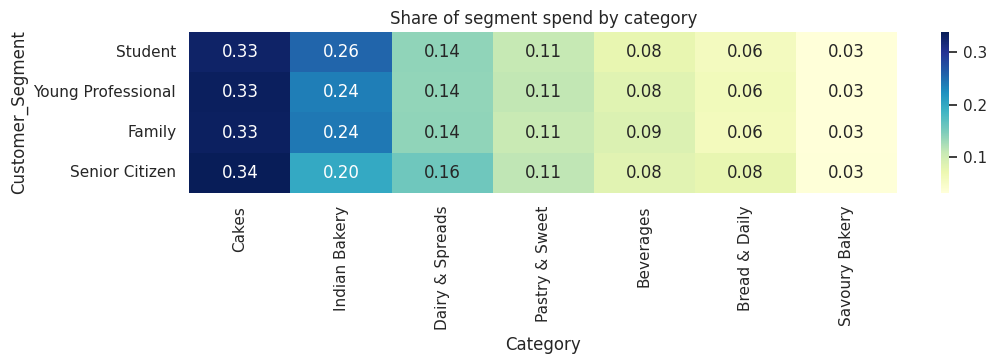

Category,Cakes,Indian Bakery,Dairy & Spreads,Pastry & Sweet,Beverages,Bread & Daily,Savoury Bakery
Customer_Segment,,,,,,,
Student,33%,26%,14%,11%,8%,6%,3%
Young Professional,33%,24%,14%,11%,8%,6%,3%
Family,33%,24%,14%,11%,9%,6%,3%
Senior Citizen,34%,20%,16%,11%,8%,8%,3%


Overall margin (profit / bill): 0.425
Negative-profit lines: 7


,lines,revenue,profit,median_unit_price,median_waste,margin,revenue_share
Category,,,,,,,
Cakes,2189,894754,340118,415.6,50.0,38.0%,33.3%
Indian Bakery,3058,648365,322790,33.5,25.0,49.8%,24.1%
Dairy & Spreads,3620,374442,127577,56.8,33.3,34.1%,13.9%
Pastry & Sweet,3577,295173,142207,40.8,33.3,48.2%,11.0%
Beverages,3219,225372,96245,48.3,33.3,42.7%,8.4%
Bread & Daily,2648,163655,72484,40.4,33.3,44.3%,6.1%
Savoury Bakery,1010,89043,42317,24.9,20.0,47.5%,3.3%


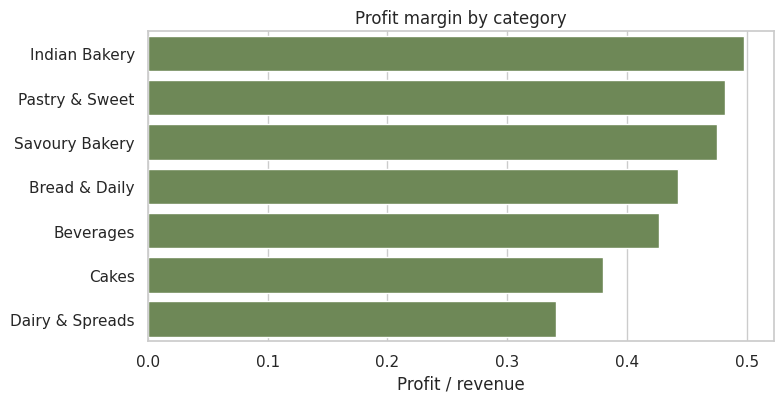

In [7]:
# Revenue share of each category inside each segment. Row shares, so segment size does not dominate.
share = pd.crosstab(
    df["Customer_Segment"], df["Category"],
    values=df["Total_Bill"], aggfunc="sum", normalize="index",
).reindex(index=SEG_ORDER, columns=CAT_ORDER)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(share, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax)
ax.set_title("Share of segment spend by category")
plt.tight_layout()
plt.show()
display(share.style.format("{:.0%}").background_gradient(cmap="YlGnBu", axis=None))

econ = df.groupby("Category", observed=True).agg(
    lines=("Product", "count"),
    revenue=("Total_Bill", "sum"),
    profit=("Profit", "sum"),
    median_unit_price=("Unit_Price", "median"),
    median_waste=("Waste_Pct", "median"),
)
econ["margin"] = econ["profit"] / econ["revenue"]
econ["revenue_share"] = econ["revenue"] / econ["revenue"].sum()
econ = econ.reindex(CAT_ORDER)
print(f"Overall margin (profit / bill): {df['Profit'].sum() / df['Total_Bill'].sum():.3f}")
print("Negative-profit lines:", int((df["Profit"] < 0).sum()))
display(
    econ.style.format({
        "revenue": "{:.0f}",
        "profit": "{:.0f}",
        "median_unit_price": "{:.1f}",
        "median_waste": "{:.1f}",
        "margin": "{:.1%}",
        "revenue_share": "{:.1%}",
    }).background_gradient(subset=["margin", "revenue_share"], cmap="YlGnBu")
)

fig, ax = plt.subplots(figsize=(8, 4.2))
margin_order = econ["margin"].sort_values(ascending=False).index.tolist()
sns.barplot(
    x=econ.loc[margin_order, "margin"], y=margin_order, color="#6d904f", ax=ax,
)
ax.set_title("Profit margin by category")
ax.set_xlabel("Profit / revenue")
plt.tight_layout()
plt.show()


**Interpretation** <br>
Personas buy the same menu. Cakes are about a third of spend in every segment. Seniors shift a few points toward dairy and bread and away from Indian bakery; students shift a few points the other way. That is a tilt, not a different bakery.

Economics differ by product, not by person. Cakes lead revenue on a thinner margin (about 38%). Indian bakery is close on profit with a margin near 50%. Dairy leads line counts and has the thinnest margin (about 34%). Overall, profit is about 42.5% of the bill, and only a handful of lines lose money. Waste is high in every category (medians in the 30s), so waste looks like a production attribute of the line rather than a segment behavior.


# **7. Correlations:** <a id="Correlations"></a>


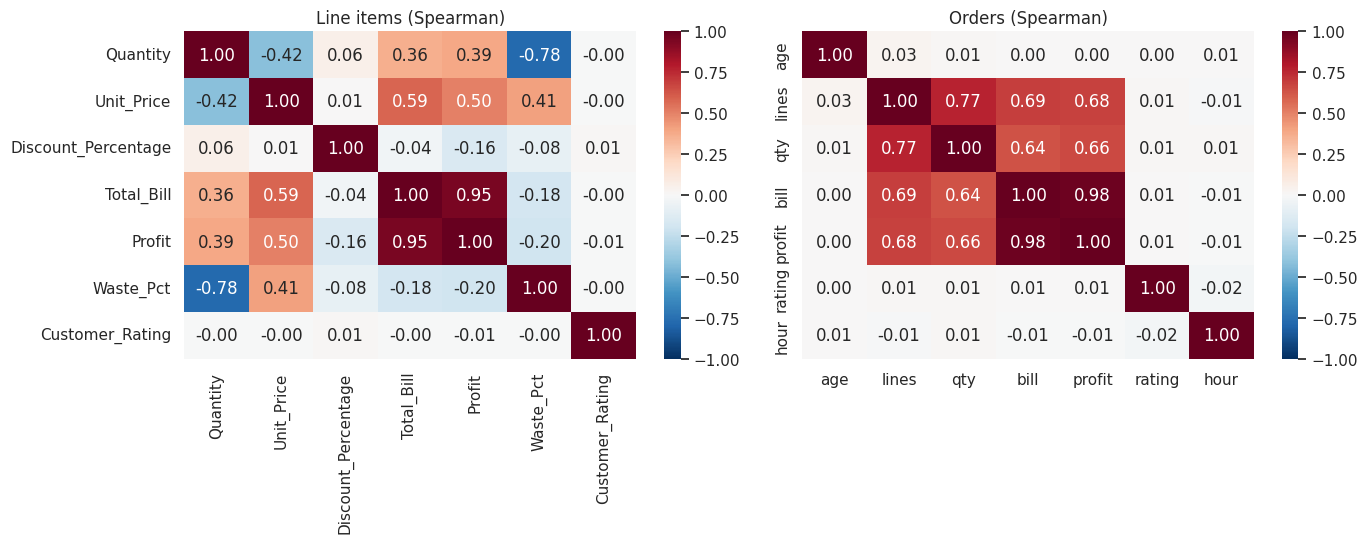

Order lines vs bill: rho=0.692, p=0.000e+00
Order rating vs bill: rho=0.006, p=0.615
Line quantity vs waste %: rho=-0.776, p=0.000e+00


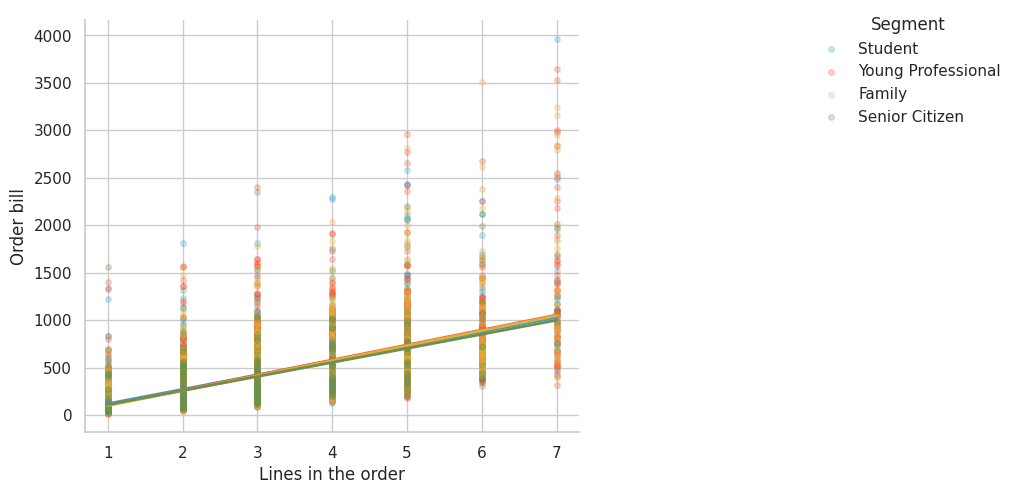

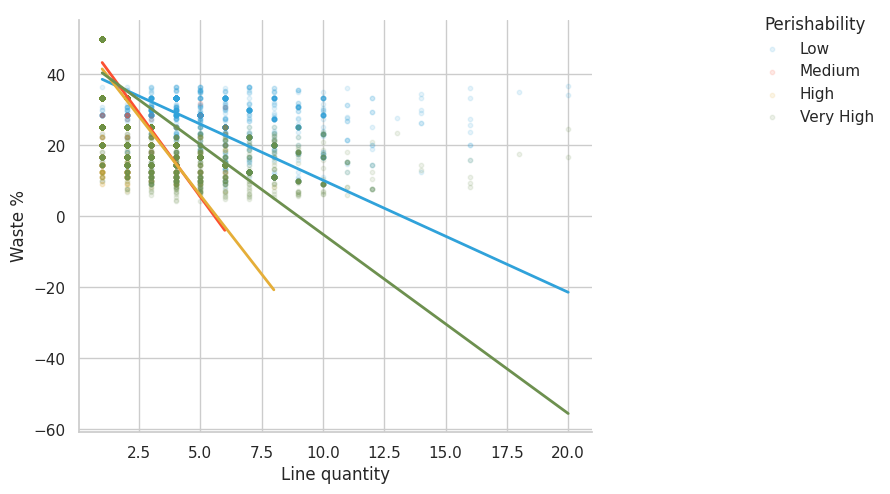

In [8]:
line_num = [
    "Quantity", "Unit_Price", "Discount_Percentage", "Total_Bill",
    "Profit", "Waste_Pct", "Customer_Rating",
]
order_num = ["age", "lines", "qty", "bill", "profit", "rating", "hour"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
sns.heatmap(
    df[line_num].corr(method="spearman"), annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
)
axes[0].set_title("Line items (Spearman)")
sns.heatmap(
    orders[order_num].corr(method="spearman"), annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1],
)
axes[1].set_title("Orders (Spearman)")
plt.tight_layout()
plt.show()

rho_lines, p_lines = stats.spearmanr(orders["lines"], orders["bill"])
rho_rating, p_rating = stats.spearmanr(orders["rating"], orders["bill"])
rho_waste, p_waste = stats.spearmanr(df["Quantity"], df["Waste_Pct"])
print(f"Order lines vs bill: rho={rho_lines:.3f}, p={p_lines:.3e}")
print(f"Order rating vs bill: rho={rho_rating:.3f}, p={p_rating:.3f}")
print(f"Line quantity vs waste %: rho={rho_waste:.3f}, p={p_waste:.3e}")

# ci omitted on the large clouds; the Spearman rows above are the uncertainty statement
g = sns.lmplot(
    data=orders, x="lines", y="bill", hue="segment", hue_order=SEG_ORDER,
    height=5, aspect=1.25, ci=None,
    scatter_kws={"alpha": 0.25, "s": 16},
    line_kws={"lw": 2},
)
g.set_axis_labels("Lines in the order", "Order bill")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Segment", frameon=False)
plt.show()

g = sns.lmplot(
    data=df, x="Quantity", y="Waste_Pct", hue="Perishability", hue_order=PERISH_ORDER,
    height=5, aspect=1.25, ci=None,
    scatter_kws={"alpha": 0.12, "s": 10},
    line_kws={"lw": 2},
)
g.set_axis_labels("Line quantity", "Waste %")
sns.move_legend(
    g, "upper left", bbox_to_anchor=(1.02, 1), title="Perishability", frameon=False,
)
plt.show()


**Interpretation** <br>
On the order, bill and profit are nearly the same variable (Spearman about 0.98): profit is the ticket scaled by a fairly tight margin, not a separate outcome. Basket length tracks the bill (ρ about 0.69), and the segment lines on the scatter sit on top of each other — longer orders cost more for every persona.

Age, hour, and rating are flat against the bill (rating ρ about 0, and the p-value is large). On the line, quantity and waste move in opposite directions (ρ about −0.62) across perishability bands: bigger lines show a lower waste percentage. Discount is a weak co-mover next to price and quantity. Rating never joins the economic cluster.


# **8. What Moves the Ticket:** <a id="Ticket"></a>


Reference levels: segment = Family, loyalty = No
Hold-out R^2, full model: 0.405
Hold-out R^2, lines only: 0.376
Hold-out R^2, calendar only: 0.038
Hold-out R^2, profile only: -0.005


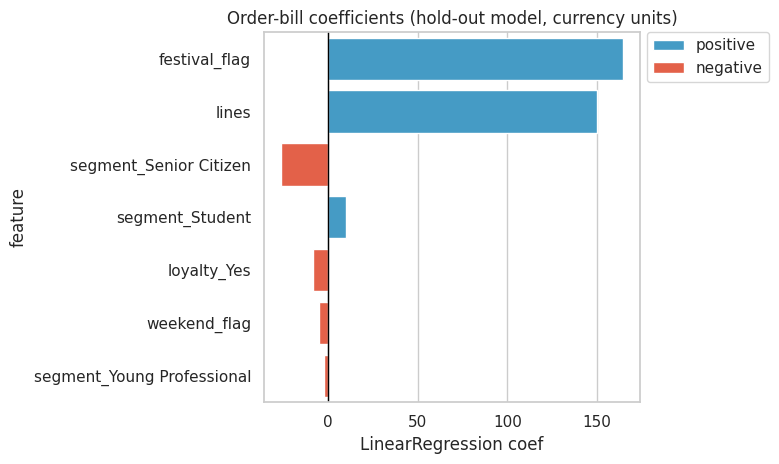

,coef
festival_flag,164.3
lines,150.2
segment_Senior Citizen,-26.2
segment_Student,10.2
loyalty_Yes,-8.5
weekend_flag,-5.2
segment_Young Professional,-2.4


In [9]:
# Mean bill in currency units. Flags stay 0/1 so a coefficient is the average shift, not a standardized one.
# Reference levels are the first sorted category: Family, and loyalty No.
orders["festival_flag"] = (orders["festival"] != "None").astype(int)
orders["weekend_flag"] = (orders["weekend"] == "Yes").astype(int)
num = ["lines", "festival_flag", "weekend_flag"]
cat = ["segment", "loyalty"]
X = orders[num + cat]
y = orders["bill"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

pre = ColumnTransformer([
    ("num", "passthrough", num),
    ("cat", OneHotEncoder(drop="first"), cat),
])
pipe = Pipeline([("pre", pre), ("lr", LinearRegression())])
pipe.fit(X_train, y_train)
names = num + list(pipe.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(cat))
coef = pd.Series(pipe.named_steps["lr"].coef_, index=names)
print("Reference levels: segment = Family, loyalty = No")
print(f"Hold-out R^2, full model: {r2_score(y_test, pipe.predict(X_test)):.3f}")

line_only = LinearRegression().fit(X_train[["lines"]], y_train)
print(f"Hold-out R^2, lines only: {r2_score(y_test, line_only.predict(X_test[['lines']])):.3f}")
cal_cols = ["festival_flag", "weekend_flag"]
cal_only = LinearRegression().fit(X_train[cal_cols], y_train)
print(f"Hold-out R^2, calendar only: {r2_score(y_test, cal_only.predict(X_test[cal_cols])):.3f}")
prof = Pipeline([
    ("pre", ColumnTransformer([("cat", OneHotEncoder(drop="first"), cat)])),
    ("lr", LinearRegression()),
])
prof.fit(X_train[cat], y_train)
print(f"Hold-out R^2, profile only: {r2_score(y_test, prof.predict(X_test[cat])):.3f}")

coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
coef_plot = coef_sorted.rename("coef").rename_axis("feature").reset_index()
coef_plot["sign"] = np.where(coef_plot["coef"] >= 0, "positive", "negative")
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(
    data=coef_plot, x="coef", y="feature", hue="sign", dodge=False,
    palette={"positive": "#30a2da", "negative": "#fc4f30"}, ax=ax,
)
ax.axvline(0, color="black", lw=1)
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
ax.set_title("Order-bill coefficients (hold-out model, currency units)")
ax.set_xlabel("LinearRegression coef")
plt.tight_layout()
plt.show()
display(coef_sorted.round(1).rename("coef").to_frame())


**Interpretation** <br>
Basket length is the ticket. Lines alone reach a hold-out R² of about 0.38; adding the calendar and the persona lifts that only to about 0.41. Profile alone (segment and loyalty) has a hold-out R² of about 0 — slightly worse than predicting the training mean. Each extra line is associated with about +150 on the mean bill. A festival order is about +164 after line count is held constant, so festival tickets are richer per line, not just longer. The weekend flag shrinks to about −5 once lines and festival are in the model: the higher weekend median is mostly a slightly longer basket plus skew, not a separate average premium. Senior versus Family is about −26, a real but small shift next to one extra line. Loyalty is about −9. The intercept is omitted on purpose; every order has at least one line, so a zero-line intercept is outside the data.


# **9. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
A line-item bakery ledger for 2023–2024: 19,321 product rows, 6,576 orders, 500 customers, three stores. Customer age, gender, segment, and loyalty are constant for each person across the whole panel.

**Working takeaways:** <br>
- Read three grains. Lines answer product economics, orders answer the basket and the calendar, customers answer whether the 500 personas buy differently. Line-item charts overweight multi-line tickets.
- Baskets are short (median 3 lines, maximum 7). The order bill is right-skewed (median about 300, mean about 409) and moves with basket length (Spearman ρ about 0.69; about +150 per extra line).
- Festival is the calendar lever that survives a control for basket length (about +164 on the mean bill). Every named festival beats the off-festival median; Ganesh Chaturthi is the volume festival, Diwali and Christmas the richest. The raw weekend median gap (about 335 versus 287) is real as a rank test and mostly disappears as an average premium once line count is included.
- Segments are age personas with overlapping edges. Median visits are 13 in every segment. Lifetime spend tracks visit count (ρ about 0.73), not loyalty. Seniors' typical ticket is lighter; the other three personas sit together. Ratings hover near 3.8 and are uncorrelated with the bill.
- The menu mix is shared: cakes are about a third of spend for every persona. Cakes lead revenue on a thinner margin; Indian bakery is close on profit with a margin near 50%; dairy is high-count and thin-margin. Profit is about 42% of the bill and correlates about 0.98 with it. Waste is high everywhere and falls as line quantity rises.
- A linear model confirms the split: lines-only hold-out R² about 0.38, full model about 0.41, segment-plus-loyalty about 0. Stores and payment method do not separate the personas.

**Open follow-ups:** <br>
- Which categories share a ticket (basket affinity), now that persona mix is known to be flat.
- Whether the festival premium is a shift into cakes or a higher price on the same products.
- Waste at product × day grain — line-level `Waste_Pct` behaves like a production attribute repeated onto the sale.
- Leave `Customer_Rating` out of any satisfaction KPI until it varies with the basket or the persona.
